# Group A – Polynomial Regression
## Can we guess a car's fuel economy from its engine power?

**The question:** if I know how powerful a car's engine is, can I guess how far it will go on a gallon of fuel?

**The data:** the *Auto MPG* dataset, which has real cars built between 1970 and 1982. For each car I use two numbers:

* **Horsepower:** how powerful the engine is. A bigger number means a stronger engine.
* **MPG (miles per gallon):** how far the car goes on one gallon of fuel. A bigger number means the car uses less fuel.

**What I will do:**
1. Look at the data
2. Learn what polynomial regression is
3. Keep some cars aside for testing
4. Compare a straight line with a curve
5. Find out how much bend is enough
6. Use the model to make guesses

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

# Make every chart clean and easy to read
plt.rcParams.update({"figure.figsize": (8, 5), "font.size": 12, "axes.grid": True, "grid.color": "#e6e5e0",
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True})
BLUE, ORANGE, GREEN = "#2a78d6", "#eb6834", "#1baf7a"

### Step 1: Look at the data
First I load the cars and look at the first few rows. Six cars have no horsepower recorded, so I remove them.

In [2]:
cars = pd.read_csv("data/mpg.csv")
cars = cars.dropna(subset=["horsepower"])

print("Number of cars:", len(cars))
cars[["name", "horsepower", "mpg"]].head()

Number of cars: 392


,name,horsepower,mpg
0,chevrolet chevelle malibu,130.0,18.0
1,buick skylark 320,165.0,15.0
2,plymouth satellite,150.0,18.0
3,amc rebel sst,150.0,16.0
4,ford torino,140.0,17.0


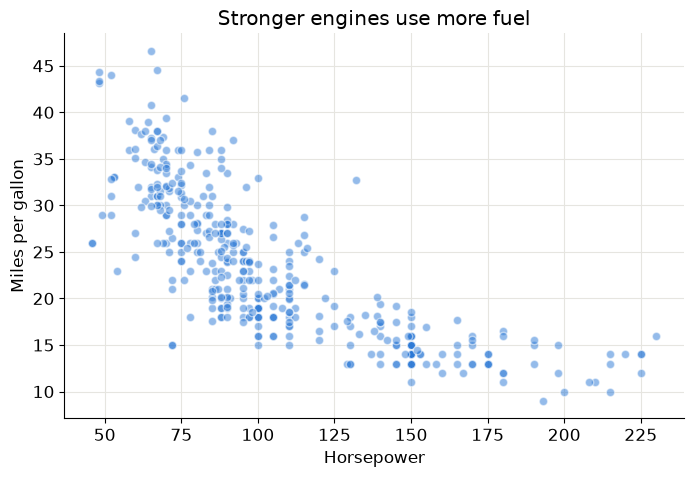

In [3]:
plt.scatter(cars["horsepower"], cars["mpg"], color=BLUE, alpha=0.5, edgecolor="white")
plt.xlabel("Horsepower")
plt.ylabel("Miles per gallon")
plt.title("Stronger engines use more fuel")
plt.show()

**What the chart shows:** each dot is one car. As engines get stronger, MPG falls quickly at first and then levels off.
The dots follow a **curve**, not a straight line.

### Step 2: What is polynomial regression?
A **regression** is a line drawn through the data so we can use it to make guesses.

* A normal (linear) regression draws a **straight line**: $mpg = b_0 + b_1 \times hp$
* A **polynomial** regression adds $hp^2$, which lets the line **bend**: $mpg = b_0 + b_1 \times hp + b_2 \times hp^2$

The numbers $b_0, b_1, b_2$ are chosen by the computer. It tries to make the line pass as close to the dots as
possible, by making the total of the squared gaps between the line and the dots as small as it can.
This is called **least squares**.

The **degree** is the biggest power used. Degree 1 is a straight line, degree 2 has one bend, and higher degrees can bend more.

### Step 3: Keep some cars aside for testing
A student who has seen the exam answers will score well, but that doesn't prove they understand the subject.
Models are the same, so I split the cars into two groups:

* **Practice cars (75%):** the model learns from these
* **Test cars (25%):** the model never sees these while learning, so they show how well it handles new cars

In [4]:
x = cars["horsepower"].values
y = cars["mpg"].values

x_practice, x_test, y_practice, y_test = train_test_split(x, y, test_size=0.25, random_state=42)

print("Practice cars:", len(x_practice))
print("Test cars:", len(x_test))

Practice cars: 294
Test cars: 98


### Step 4: Compare a straight line with a curve
`np.polyfit` finds the best line for a chosen degree. Then I check each one on the test cars using two scores:

* **Average error:** how many MPG the guess is wrong by, on average. Lower is better.
* **R² (shown as a percentage):** how much of the difference between cars the model explains. Higher is better, and 100% would be perfect.

In [5]:
line = np.poly1d(np.polyfit(x_practice, y_practice, 1))    # degree 1: a straight line
curve = np.poly1d(np.polyfit(x_practice, y_practice, 2))   # degree 2: a curve

for name, model in [("Straight line", line), ("Curve", curve)]:
    guesses = model(x_test)
    print(f"{name}: average error = {mean_absolute_error(y_test, guesses):.1f} mpg, R² = {r2_score(y_test, guesses):.0%}")

Straight line: average error = 3.8 mpg, R² = 57%
Curve: average error = 3.2 mpg, R² = 66%


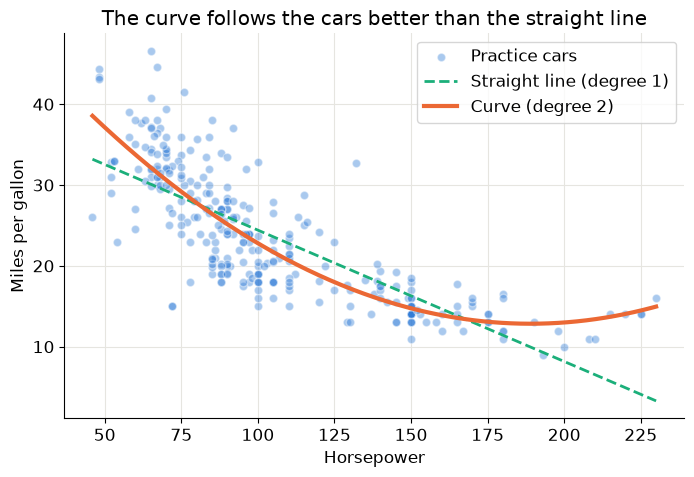

In [6]:
hp_range = np.linspace(46, 230, 300)    # evenly spaced horsepower values, used to draw smooth lines

plt.scatter(x_practice, y_practice, color=BLUE, alpha=0.4, edgecolor="white", label="Practice cars")
plt.plot(hp_range, line(hp_range), color=GREEN, lw=2, ls="--", label="Straight line (degree 1)")
plt.plot(hp_range, curve(hp_range), color=ORANGE, lw=3, label="Curve (degree 2)")
plt.xlabel("Horsepower")
plt.ylabel("Miles per gallon")
plt.title("The curve follows the cars better than the straight line")
plt.legend()
plt.show()

**What this shows:** the straight line is too stiff to follow the cars. This is called **underfitting**.
The curve follows them much better. Its average error is lower (about 3.2 mpg instead of 3.8), and it explains
more of the differences between cars (66% instead of 57%).

### Step 5: How much bend is enough?
If one bend helps, are more bends better? I try several degrees and score each one on the practice cars and the test cars.

In [7]:
rows = []
for degree in [1, 2, 3, 5, 10, 15]:
    model = np.poly1d(np.polyfit(x_practice, y_practice, degree))
    rows.append({"Degree": degree,
                 "Practice R²": f"{r2_score(y_practice, model(x_practice)):.0%}",
                 "Test R²": f"{r2_score(y_test, model(x_test)):.0%}"})

pd.DataFrame(rows).set_index("Degree")

,Practice R²,Test R²
Degree,,
1,61%,57%
2,69%,66%
3,69%,66%
5,70%,67%
10,71%,65%
15,72%,65%


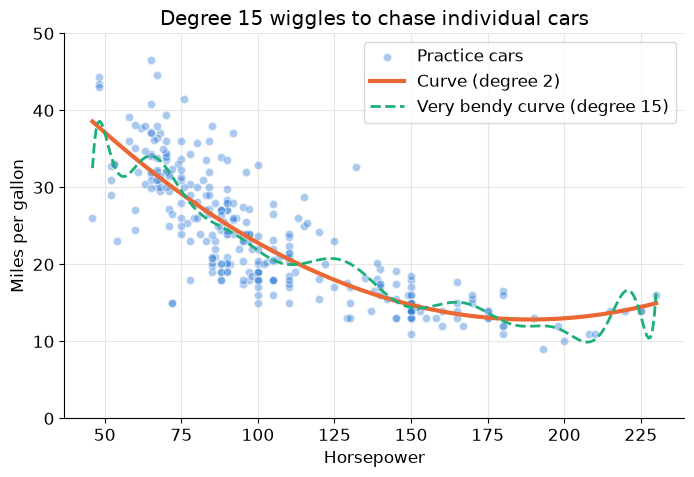

In [8]:
very_bendy = np.poly1d(np.polyfit(x_practice, y_practice, 15))

plt.scatter(x_practice, y_practice, color=BLUE, alpha=0.4, edgecolor="white", label="Practice cars")
plt.plot(hp_range, curve(hp_range), color=ORANGE, lw=3, label="Curve (degree 2)")
plt.plot(hp_range, very_bendy(hp_range), color=GREEN, lw=2, ls="--", label="Very bendy curve (degree 15)")
plt.ylim(0, 50)
plt.xlabel("Horsepower")
plt.ylabel("Miles per gallon")
plt.title("Degree 15 wiggles to chase individual cars")
plt.legend()
plt.show()

**What this shows:**
* Going from degree 1 to degree 2 is the big jump: the test score rises from 57% to 66%.
* After that, the test score hardly changes. It stays between 65% and 67%.
* The practice score keeps rising, up to 72%, because a bendier line can always get closer to the cars it has already seen.
* The degree 15 line wiggles to chase individual cars, especially at the edges of the chart where there are few cars. This is called **overfitting**. It is like memorising the answers instead of understanding the subject.

**My choice is degree 2.** Degree 5 scores 1% higher on the test cars, but that gain is too small to justify a more complicated model. Degree 2 is the simplest model that follows the curve.

### Step 6: Use the model
Here is the final degree 2 model written as a formula. I can now give it a horsepower and it will guess the MPG.

In [9]:
b2, b1, b0 = curve.coefficients
print(f"mpg = {b0:.2f} + ({b1:.4f} × hp) + ({b2:.6f} × hp²)")
print()

for hp in [70, 100, 150, 200]:
    print(f"A {hp} hp car is guessed to do {curve(hp):.1f} mpg")

mpg = 57.78 + (-0.4757 × hp) + (0.001259 × hp²)

A 70 hp car is guessed to do 30.7 mpg
A 100 hp car is guessed to do 22.8 mpg
A 150 hp car is guessed to do 14.7 mpg
A 200 hp car is guessed to do 13.0 mpg


### Conclusion
* Engine power and fuel economy follow a **curve**, so a straight line is not good enough.
* A **degree 2** polynomial works best here because it is simple and fits well. For example, it guesses about 23 mpg for a 100 hp car and about 13 mpg for a 200 hp car.
* The model explains about **66%** of the differences between test cars. The rest probably comes from things it doesn't know about, like the car's weight and age.
* **Main lesson:** always judge a model on data it has not seen. A model can keep improving on its practice data without getting any better on new data.